In [1]:
import matplotlib.pyplot as plt
import sys
sys.path.insert(1, '../')
import util

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np

In [3]:
%run "../scripts/Simulations_extended_SSPs.py"

KeyboardInterrupt: 

In [4]:
folder= "../../Data/Simulations/Extended SSPs/"
scenarios = ['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp585'] # the manuscript doesn't contain ssp534-over
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
# scenarios = ['ssp119', 'ssp126','ssp534-over']
D = np.array([[np.loadtxt(folder+"D_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))]).transpose((0,2,1,3))
D_noint = np.array([[np.loadtxt(folder+"D_no_interaction_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))])

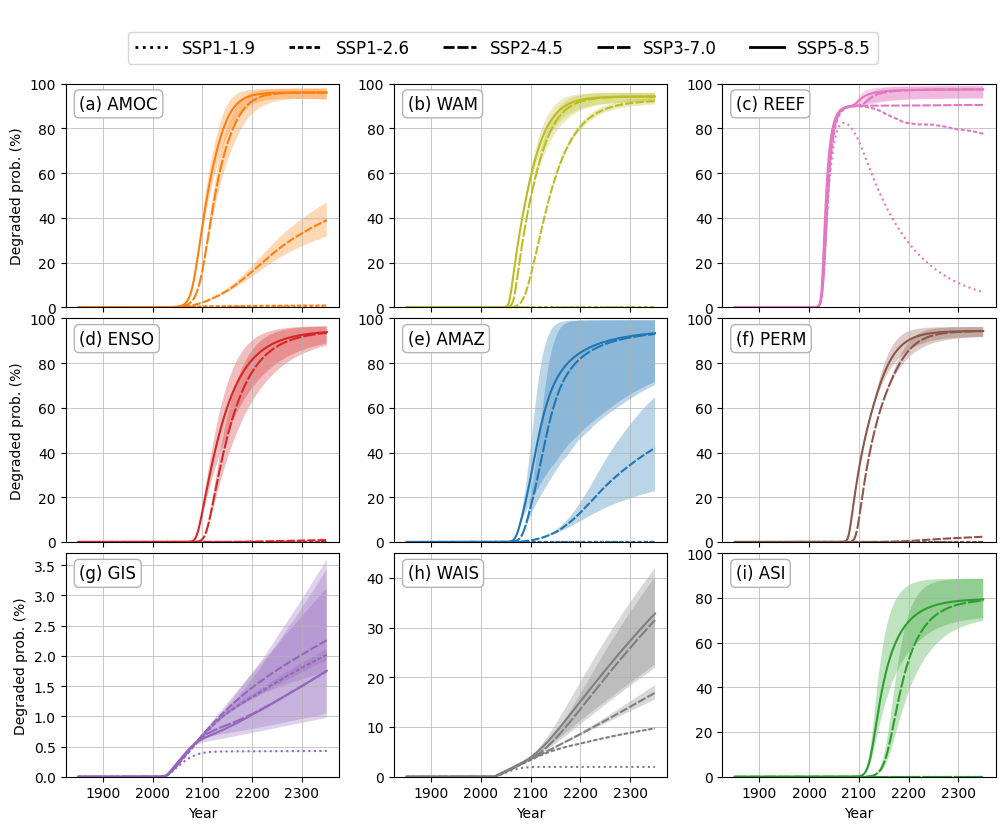

In [5]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TEs = df_TEs.index.to_numpy()
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
ylims = [[0,100]]*6+[[0,3.7], [0,45], [0,100]]
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    axs[i_ax//3,i_ax%3].set_ylim(ylims[i_ax])
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        # axs[i_ax//3,i_ax%3].plot(years,D_noint[j,i,:]*100,color='k',lw=0.5)
        # axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
        #                          c=colors[i], ls=linestyles[j],
        #                          lw=1)
        axs[i_ax//3,i_ax%3].fill_between(years,
                                         np.quantile(D[j,:,i,:],0.05,axis=0)*100,
                                         np.quantile(D[j,:,i,:],0.95,axis=0)*100,
                                         color=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=util.plot.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)
folder_out = '../../Figures/Manuscript/'
fig.savefig(folder_out+'extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

In [13]:
scenarios = ['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp585'] # the manuscript doesn't contain ssp534-over
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
# scenarios = ['ssp119', 'ssp126','ssp534-over']
D_saved = np.array([[np.loadtxt("../../Data/Simulations/Extended SSPs/D_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))]).transpose((0,2,1,3))

In [1]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TEs = df_TEs.index.to_numpy()
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,D_saved[j,:,i,:].mean(axis=0)*100,
                                 c=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        # axs[i_ax//3,i_ax%3].plot(years,D_noint[j,i,:]*100,color='k',lw=0.5)
        # axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
        #                          c=colors[i], ls=linestyles[j],
        #                          lw=1)
        axs[i_ax//3,i_ax%3].fill_between(years,
                                         np.quantile(D_saved[j,:,i,:],0.05,axis=0)*100,
                                         np.quantile(D_saved[j,:,i,:],0.95,axis=0)*100,
                                         color=util.plot.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=util.plot.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)
# fig.savefig(folder_out+'extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

NameError: name 'np' is not defined

In [16]:
D.shape

(6, 500, 9, 501)

In [17]:
D_saved.shape

(5, 500, 9, 501)